# Support Vector Classifier - SVC

In [4]:
# this is completely for the classifier dataset and i use the SVC - support vector classifier -> approach
# and the holistic idea about what i understand about the SVM

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import plotly.express as px


from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [3]:
# creating a dataset that looks like circle shape category distribution

# first block (radius 10)

x = np.linspace(-5.0, 5.0, 100) # --> 100 elements
y = np.sqrt(10**2 - x**2)       # --> 100 elements
y=np.hstack([y,-y])
x=np.hstack([x,-x])

In [4]:
# second block (radius 5)

x1 = np.linspace(-5.0, 5.0, 100) # --> 100 elements
y1 = np.sqrt(5**2 - x1**2)       # --> 100 elements
y1=np.hstack([y1,-y1])
x1=np.hstack([x1,-x1])

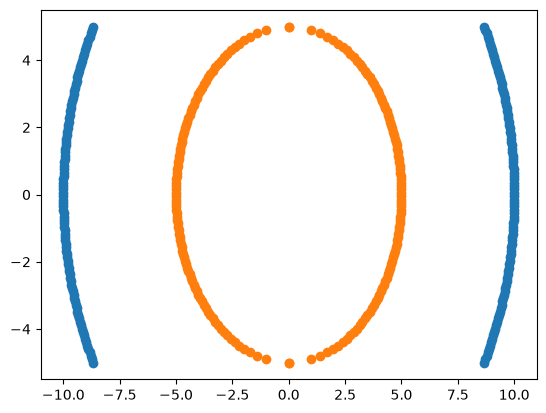

In [5]:
# ploting these two data

plt.scatter(y,x)
plt.scatter(y1,x1)

# this is in 2dimensional view and in this the linear will make mistake of taking the boundary line.

In [6]:
# combine the separate circle data into single table

df1 = pd.DataFrame(np.vstack([y,x]).T, columns=['X1','X2']) # --> 200 data points
df2 = pd.DataFrame(np.vstack([y1,x1]).T, columns=['X1','X2']) # --> 200 data points
                  
# assigning each dataframe into classes
df1['y']=0
df2['y']=1

# merging both dataframe into single table
df = pd.concat([df1, df2], ignore_index=True)

df.head()

,X1,X2,y
0,8.660254,-5.00000,0
1,8.717792,-4.89899,0
2,8.773790,-4.79798,0
3,8.828277,-4.69697,0
4,8.881281,-4.59596,0


In [7]:
df['y'].value_counts()

y
0    200
1    200
Name: count, dtype: int64

In [8]:
# this is polynomial feature mapping to create a 3D view space.

df['X1_sq'] = df['X1']**2
df['X2_sq'] = df['X2']**2


# for 3 dimensional , need three coordinates (X,Y,Z)
# this becomes the calculates Z-axis value
# and this is exactly same as the parameter that setting in the kernel trick in the SVC , degree = 2 
df['X1*X2'] = (df['X1'] * df['X2'])
df.head()

# and the dataset is ready to train and test

,X1,X2,y,X1_sq,X2_sq,X1*X2
0,8.660254,-5.00000,0,75.000000,25.000000,-43.301270
1,8.717792,-4.89899,0,75.999898,24.000102,-42.708375
2,8.773790,-4.79798,0,76.979390,23.020610,-42.096467
3,8.828277,-4.69697,0,77.938476,22.061524,-41.466150
4,8.881281,-4.59596,0,78.877155,21.122845,-40.818009


In [9]:
x = df.drop('y',axis = 1) # --> independent features
y = df['y'] # --> dependent features

In [10]:
# train test split
x_train, x_test, y_train, y_test = train_test_split(
    x,y, test_size = 0.25, random_state = 42
)


In [11]:
# the actuall 2d into 3d view

fig = px.scatter_3d(df, x = 'X1', y = 'X2', z = 'X1*X2',color='y')
fig.show(renderer='browser')

In [18]:
# actual 3d into 3d view

fig = px.scatter_3d(df, x = 'X1_sq', y = 'X2_sq', z = 'X1*X2', color = 'y')
fig.show(renderer='browser')

In [5]:
# far now , i manually engineered new features (X1_sq, X2_sq, X1*X2) to lift the data into 3d space. like --> 2d data classes into 3d classes view.

# in same side in SVC --> just setting the parameter degree = 2 , it does the same job like this formula (X1_sq, X2_sq, X1*X2)

# and model will easily set the support vector points and setup the marginal plane and set the decision boundary easily.

# model will able to identified the new data easily by using the decision boundary.

In [6]:
# 1. from now, i use the SVM's SVC approach for this to solve the classification problems
# 2. SVC does this job completely by using the kernel trick.
# 3. like (kernel='ploy' or kernel='rbf', kernel='sigmoid')
# 4. the SVC will automatically calculates internally and projects the data into higher dimensional space, behind the scenes using the "kernel trick" and no need to add any others extras columns like previous one.



# # setting degree = 2 , the polynomial kernel automatically generates three things:

# --> X1_sq = how X1 interact with itself
# --> X2_sq = how X2 interact with itself
# --> X1*X2 = how X1 and X2 interact with each other

# --> without this X1*X2, model could only grow the data straight up or sideways.
# --> by multiplying them together allows the model to handle diagonal twists and rotations, ensuring it can perfectly separate shapes even it they are tilted.

In [25]:
# these are the different kernel in the SVM and it globally applicable for SVM methods like SVC and SVM
# and there are many diff kernel's parameter tuning are there like
# gamma
# c_value -->  this one is default setting for all kernal's parameter

In [130]:
model = SVC(kernel='linear')
model.fit(x_train, y_train)
y_pred = model.predict(x_test)
accuracy_score(y_test, y_pred)

1.0

In [131]:
model = SVC(kernel='poly')
model.fit(x_train, y_train)
y_pred = model.predict(x_test)
accuracy_score(y_test, y_pred)

1.0

In [132]:
model = SVC(kernel='rbf')
model.fit(x_train, y_train)
y_pred = model.predict(x_test)
accuracy_score(y_test, y_pred)

1.0

In [26]:
model = SVC(kernel='sigmoid')
model.fit(x_train, y_train)
y_pred = model.predict(x_test)
accuracy_score(y_test, y_pred)

1.0

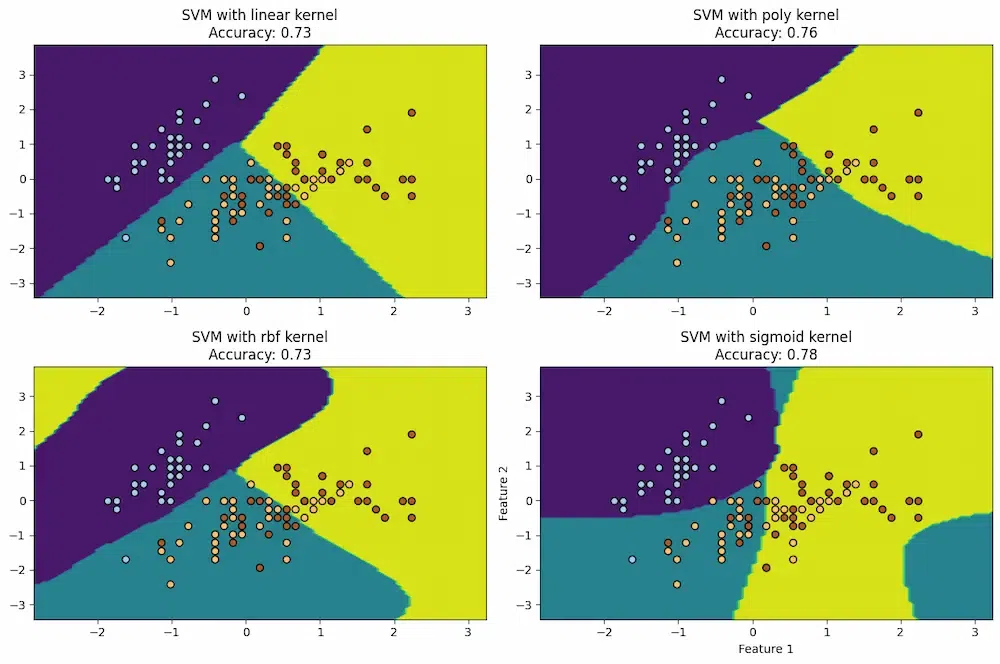

In [3]:
# these are the diff kernel looks like


from IPython.display import Image, display
img = r"E:\Machine Learning\My notes\Kernels Types.webp"
display(Image(filename = img, width = 600))

# holistic understanding about the SVM's and the strategy

In [29]:
# so far now what i understand the hoslistic idea about the SVM is 

# in this SVM there are two main model to solve the different data format like the regression and classification.
# the SVM's main strategy and this model hook is all about the kernel and 
# the kernel's parameters and the support vector and finally the margins plane and decision boudries line.

# each kernel act as different math and strategy/algorithm.
# if want to try in regression data means use the SVR model to predict the linear data.
# if want to set the decision boundaries in the categorical data that means the classification, use the SVC and their kernel and parameters

# so the main matter is about the setting the proper support vector , marginal plane and inbetween the decision boundary to make the model more confidence.
# then, about the SVM -> svc and svr uses the default approach of OVO(one vs one --> Binary classification)
# there is completely another approach called "linearsvc" like the SVM's SVC & SVR and it uses for when the data is can be split by the strainght line and 
# also the data is massive in this scenerio means we can go with this model

# overall this is what i understand about the SVM and about the internal kernel and support vector and maginal plane